In [4]:
import cv2
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt

In [5]:
from pathlib import Path

cwd = Path.cwd()

if (cwd / "datasets" / "Celeb-DF-v2").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "datasets" / "Celeb-DF-v2").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Could not find datasets/Celeb-DF-v2. "
        "Make sure notebook is inside the notebooks folder."
    )

DATASET_DIR = PROJECT_ROOT / "datasets" / "Celeb-DF-v2"
RESULTS_DIR = PROJECT_ROOT / "results"

PROCESSED_DIR = RESULTS_DIR / "processed_faces"

print("Project:", PROJECT_ROOT)
print("Dataset:", DATASET_DIR)
print("Processed faces:", PROCESSED_DIR)

Project: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project
Dataset: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\datasets\Celeb-DF-v2
Processed faces: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\processed_faces


In [6]:
# load metadata
metadata_path = RESULTS_DIR / "cleaned_video_metadata.csv"

if not metadata_path.exists():
    raise FileNotFoundError(
        f"Metadata file not found: {metadata_path}"
    )

cleaned_metadata_df = pd.read_csv(metadata_path)

print("Shape:", cleaned_metadata_df.shape)
display(cleaned_metadata_df.head())



Shape: (6529, 11)


,video_path,filename,folder,fps,frame_count,width,height,duration,label,class_name,resolution
0,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000.mp4,Celeb-real,30.0,469.0,942.0,500.0,15.633333,0,Real,942x500
1,..\datasets\Celeb-DF-v2\Celeb-real\id0_0001.mp4,id0_0001.mp4,Celeb-real,30.0,303.0,942.0,500.0,10.100000,0,Real,942x500
2,..\datasets\Celeb-DF-v2\Celeb-real\id0_0002.mp4,id0_0002.mp4,Celeb-real,30.0,350.0,942.0,500.0,11.666667,0,Real,942x500
3,..\datasets\Celeb-DF-v2\Celeb-real\id0_0003.mp4,id0_0003.mp4,Celeb-real,30.0,529.0,942.0,500.0,17.633333,0,Real,942x500
4,..\datasets\Celeb-DF-v2\Celeb-real\id0_0004.mp4,id0_0004.mp4,Celeb-real,30.0,326.0,942.0,500.0,10.866667,0,Real,942x500


In [7]:
# check columns 
print(cleaned_metadata_df.columns.tolist())

['video_path', 'filename', 'folder', 'fps', 'frame_count', 'width', 'height', 'duration', 'label', 'class_name', 'resolution']


In [8]:
# check label 
print(cleaned_metadata_df["label"].value_counts())

if "class_name" in cleaned_metadata_df.columns:
    print("\nClass names:")
    print(cleaned_metadata_df["class_name"].value_counts())

label
1    5639
0     890
Name: count, dtype: int64

Class names:
class_name
Deepfake    5639
Real         890
Name: count, dtype: int64


In [9]:
# extraction setting 
FRAMES_PER_VIDEO = 10
TARGET_SIZE = (224, 224)
FACE_PADDING = 0.20

print("Frames per video:", FRAMES_PER_VIDEO)
print("Target size:", TARGET_SIZE)
print("Face padding:", FACE_PADDING)

Frames per video: 10
Target size: (224, 224)
Face padding: 0.2


In [10]:
# Haar Cascade
FRAMES_PER_VIDEO = 10

CASCADE_PATH = PROJECT_ROOT / "notebooks" / "haarcascade_frontalface_default.xml"

if not CASCADE_PATH.exists():
    raise FileNotFoundError(
        f"Haar Cascade not found: {CASCADE_PATH}"
    )

face_cascade = cv2.CascadeClassifier(str(CASCADE_PATH))

if face_cascade.empty():
    raise RuntimeError("Failed to load Haar Cascade.")

print("Face detector loaded successfully.")

Face detector loaded successfully.


In [11]:

# ============================================================
# FIXED FACE DETECTION AND EXTRACTION FUNCTIONS
# ============================================================

def detect_faces(frame):

    if frame is None or frame.size == 0:
        return []

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.05,
        minNeighbors=4,
        minSize=(40, 40)
    )

    return faces


def crop_face_with_padding(frame, box, padding=0.30):

    x, y, w, h = map(int, box)

    center_x = x + w // 2
    center_y = y + h // 2

    side = int(max(w, h) * (1 + 2 * padding))
    half = side // 2

    x1 = max(0, center_x - half)
    y1 = max(0, center_y - half)

    x2 = min(frame.shape[1], center_x + half)
    y2 = min(frame.shape[0], center_y + half)

    face = frame[y1:y2, x1:x2]

    if face.size == 0:
        return None

    face = cv2.resize(
        face,
        TARGET_SIZE,
        interpolation=cv2.INTER_AREA
    )

    if np.std(face) < 3:
        return None

    return face


def extract_faces_from_video(
    video_path,
    num_frames=10,
    target_size=(224, 224),
    padding=0.30
):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        return []

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    if total_frames <= 0:
        cap.release()
        return []

    frame_indices = np.unique(
        np.linspace(
            0,
            total_frames - 1,
            num_frames,
            dtype=int
        )
    )

    extracted_faces = []

    for frame_idx in frame_indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(frame_idx)
        )

        success, frame = cap.read()

        if not success:
            continue

        faces = detect_faces(frame)

        if len(faces) == 0:
            continue

        largest_face = max(
            faces,
            key=lambda box: box[2] * box[3]
        )

        face = crop_face_with_padding(
            frame,
            largest_face,
            padding
        )

        if face is not None:
            extracted_faces.append(
                (int(frame_idx), face)
            )

    cap.release()

    return extracted_faces


# day 8

In [12]:
# first 5 video 

test_df = cleaned_metadata_df.head(5)

for _, row in test_df.iterrows():

    video_path = PROJECT_ROOT / row["video_path"]

    print("\nVideo:", video_path)

    faces = extract_faces_from_video(
        video_path,
        num_frames=FRAMES_PER_VIDEO,
        target_size=TARGET_SIZE,
        padding=FACE_PADDING
    )

    print("Faces extracted:", len(faces))


Video: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4
Faces extracted: 0

Video: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\..\datasets\Celeb-DF-v2\Celeb-real\id0_0001.mp4
Faces extracted: 0

Video: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\..\datasets\Celeb-DF-v2\Celeb-real\id0_0002.mp4
Faces extracted: 0

Video: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\..\datasets\Celeb-DF-v2\Celeb-real\id0_0003.mp4
Faces extracted: 0

Video: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\..\datasets\Celeb-DF-v2\Celeb-real\id0_0004.mp4
Faces extracted: 0


In [13]:
# Check one video properly

row = cleaned_metadata_df.iloc[0]

print("Metadata video_path:")
print(repr(row["video_path"]))

video_path = PROJECT_ROOT / row["video_path"]

print("\nFinal video path:")
print(video_path)

print("\nDoes file exist?")
print(video_path.exists())

cap = cv2.VideoCapture(str(video_path))

print("\nVideo opened?")
print(cap.isOpened())

frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print("Frame count:", frame_count)

success, frame = cap.read()

print("Frame read successfully?", success)

if success:
    print("Frame shape:", frame.shape)

    faces = detect_faces(frame)

    print("Faces detected in first frame:", len(faces))

cap.release()

Metadata video_path:
'..\\datasets\\Celeb-DF-v2\\Celeb-real\\id0_0000.mp4'

Final video path:
c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4

Does file exist?
False

Video opened?
False
Frame count: -1
Frame read successfully? False


In [14]:
# Fix video paths

from pathlib import Path

def fix_video_path(path_string):
    path = Path(str(path_string))

    # Remove leading ".." if metadata paths were created
    # relative to the notebooks folder
    if path.parts and path.parts[0] == "..":
        path = Path(*path.parts[1:])

    return PROJECT_ROOT / path


cleaned_metadata_df["full_video_path"] = (
    cleaned_metadata_df["video_path"]
    .apply(fix_video_path)
)

print(cleaned_metadata_df["full_video_path"].iloc[0])
print(
    "Exists:",
    cleaned_metadata_df["full_video_path"].iloc[0].exists()
)

c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4
Exists: True


In [15]:
video_path = cleaned_metadata_df["full_video_path"].iloc[0]

print("Video:", video_path)
print("Exists:", video_path.exists())

cap = cv2.VideoCapture(str(video_path))

print("Video opened:", cap.isOpened())

success, frame = cap.read()

print("Frame read:", success)

if success:
    print("Frame shape:", frame.shape)

    faces = detect_faces(frame)

    print("Faces detected:", len(faces))

cap.release()

Video: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4
Exists: True
Video opened: True
Frame read: True
Frame shape: (500, 942, 3)
Faces detected: 1


In [16]:
# Visual check
sample_faces = []

for _, row in test_df.iterrows():

    video_path = PROJECT_ROOT / row["video_path"]

    faces = extract_faces_from_video(
        video_path,
        num_frames=FRAMES_PER_VIDEO,
        target_size=TARGET_SIZE,
        padding=FACE_PADDING
    )

    sample_faces.extend(faces[:2])

    if len(sample_faces) >= 6:
        break


    plt.figure(figsize=(12, 8))

for i, face in enumerate(sample_faces[:6]):

    plt.subplot(2, 3, i + 1)

    face_rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

    plt.imshow(face_rgb)
    plt.axis("off")
    plt.title(f"Face {i+1}")

plt.tight_layout()
plt.show()

<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

# DAY 9 save extracted faces


In [17]:
PROCESSED_DIR_V2 = RESULTS_DIR / "processed_faces_v2"

REAL_DIR_V2 = PROCESSED_DIR_V2 / "real"
FAKE_DIR_V2 = PROCESSED_DIR_V2 / "deepfake"

REAL_DIR_V2.mkdir(parents=True, exist_ok=True)
FAKE_DIR_V2.mkdir(parents=True, exist_ok=True)

print("Real folder:", REAL_DIR_V2)
print("Fake folder:", FAKE_DIR_V2)
print("Folders created successfully!")

Real folder: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\processed_faces_v2\real
Fake folder: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\processed_faces_v2\deepfake
Folders created successfully!


In [18]:

# ============================================================
# DAY 9: FIXED FULL FACE EXTRACTION AND SAVING
# ============================================================

# Create separate folders for corrected crops
PROCESSED_DIR_V2 = RESULTS_DIR / "processed_faces_v2"

REAL_DIR_V2 = PROCESSED_DIR_V2 / "real"
FAKE_DIR_V2 = PROCESSED_DIR_V2 / "deepfake"

REAL_DIR_V2.mkdir(parents=True, exist_ok=True)
FAKE_DIR_V2.mkdir(parents=True, exist_ok=True)

extraction_records_v2 = []

failed_videos_v2 = []

for idx, row in cleaned_metadata_df.iterrows():

    video_path = Path(row["full_video_path"])

    if not video_path.exists():
        failed_videos_v2.append(str(video_path))
        continue

    label = int(row["label"])

    if label == 0:
        output_dir = REAL_DIR_V2
        class_name = "real"
    else:
        output_dir = FAKE_DIR_V2
        class_name = "deepfake"

    # Unique video name includes source folder
    video_id = (
        str(row["folder"]) + "__" +
        Path(row["filename"]).stem
    )

    faces = extract_faces_from_video(
        video_path,
        num_frames=FRAMES_PER_VIDEO,
        target_size=TARGET_SIZE,
        padding=0.30
    )

    for face_idx, (frame_idx, face) in enumerate(faces):

        filename = (
            f"{video_id}_frame_{frame_idx:06d}.jpg"
        )

        output_path = output_dir / filename

        if not cv2.imwrite(str(output_path), face):
            continue

        extraction_records_v2.append({
            "video_path": str(video_path),
            "video_id": video_id,
            "face_path": str(
                output_path.relative_to(PROJECT_ROOT)
            ),
            "label": label,
            "class_name": class_name,
            "frame_index": frame_idx
        })

    if (idx + 1) % 100 == 0:
        print(
            f"Processed {idx+1}/{len(cleaned_metadata_df)} "
            f"| Faces saved: {len(extraction_records_v2)}"
        )

# Save new metadata
face_metadata_v2 = pd.DataFrame(extraction_records_v2)

face_metadata_v2.to_csv(
    RESULTS_DIR / "face_metadata_v2.csv",
    index=False
)

print("\nEXTRACTION COMPLETE")
print("Total videos:", len(cleaned_metadata_df))
print("Failed videos:", len(failed_videos_v2))
print("Total face crops:", len(face_metadata_v2))
print(face_metadata_v2["class_name"].value_counts())
print("Metadata: results/face_metadata_v2.csv")


Processed 100/6529 | Faces saved: 990
Processed 200/6529 | Faces saved: 1970
Processed 300/6529 | Faces saved: 2961
Processed 400/6529 | Faces saved: 3956
Processed 500/6529 | Faces saved: 4949
Processed 600/6529 | Faces saved: 5926
Processed 700/6529 | Faces saved: 6926
Processed 800/6529 | Faces saved: 7925
Processed 900/6529 | Faces saved: 8925
Processed 1000/6529 | Faces saved: 9925
Processed 1100/6529 | Faces saved: 10925
Processed 1200/6529 | Faces saved: 11925
Processed 1300/6529 | Faces saved: 12925
Processed 1400/6529 | Faces saved: 13925
Processed 1500/6529 | Faces saved: 14925
Processed 1600/6529 | Faces saved: 15924
Processed 1700/6529 | Faces saved: 16918
Processed 1800/6529 | Faces saved: 17911
Processed 1900/6529 | Faces saved: 18905
Processed 2000/6529 | Faces saved: 19905
Processed 2100/6529 | Faces saved: 20905
Processed 2200/6529 | Faces saved: 21905
Processed 2300/6529 | Faces saved: 22904
Processed 2400/6529 | Faces saved: 23894
Processed 2500/6529 | Faces saved: 2

In [27]:

# ============================================================
# DAY 9: VERIFY EXTRACTED FACE CROPS
# ============================================================

import os
import cv2
import pandas as pd
from pathlib import Path

# 1. Check metadata
print("METADATA SHAPE:", face_metadata_v2.shape)

print("\nCLASS DISTRIBUTION:")
print(face_metadata_v2["class_name"].value_counts())

# 2. Check missing values
print("\nMISSING VALUES:")
print(face_metadata_v2.isnull().sum())

# 3. Check image files
face_metadata_v2["file_exists"] = (
    face_metadata_v2["face_path"].apply(
        lambda p: (
            PROJECT_ROOT / p
        ).exists()
    )
)

print("\nIMAGE FILE CHECK:")
print(face_metadata_v2["file_exists"].value_counts())

# 4. Check image dimensions
sample_paths = face_metadata_v2["face_path"].head(10)

print("\nSAMPLE IMAGE DIMENSIONS:")

for path in sample_paths:
    image_path = PROJECT_ROOT / path
    image = cv2.imread(str(image_path))

    if image is not None:
        print(image.shape)
    else:
        print("Unreadable:", path)

# 5. Save verification report
verification_path = RESULTS_DIR / "day9_face_verification.csv"

face_metadata_v2.to_csv(
    verification_path,
    index=False
)

print("\nVerification saved:", verification_path)


METADATA SHAPE: (64944, 6)

CLASS DISTRIBUTION:
class_name
deepfake    56146
real         8798
Name: count, dtype: int64

MISSING VALUES:
video_path     0
video_id       0
face_path      0
label          0
class_name     0
frame_index    0
dtype: int64

IMAGE FILE CHECK:
file_exists
True    64944
Name: count, dtype: int64

SAMPLE IMAGE DIMENSIONS:
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)
(224, 224, 3)

Verification saved: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\day9_face_verification.csv


# day 10


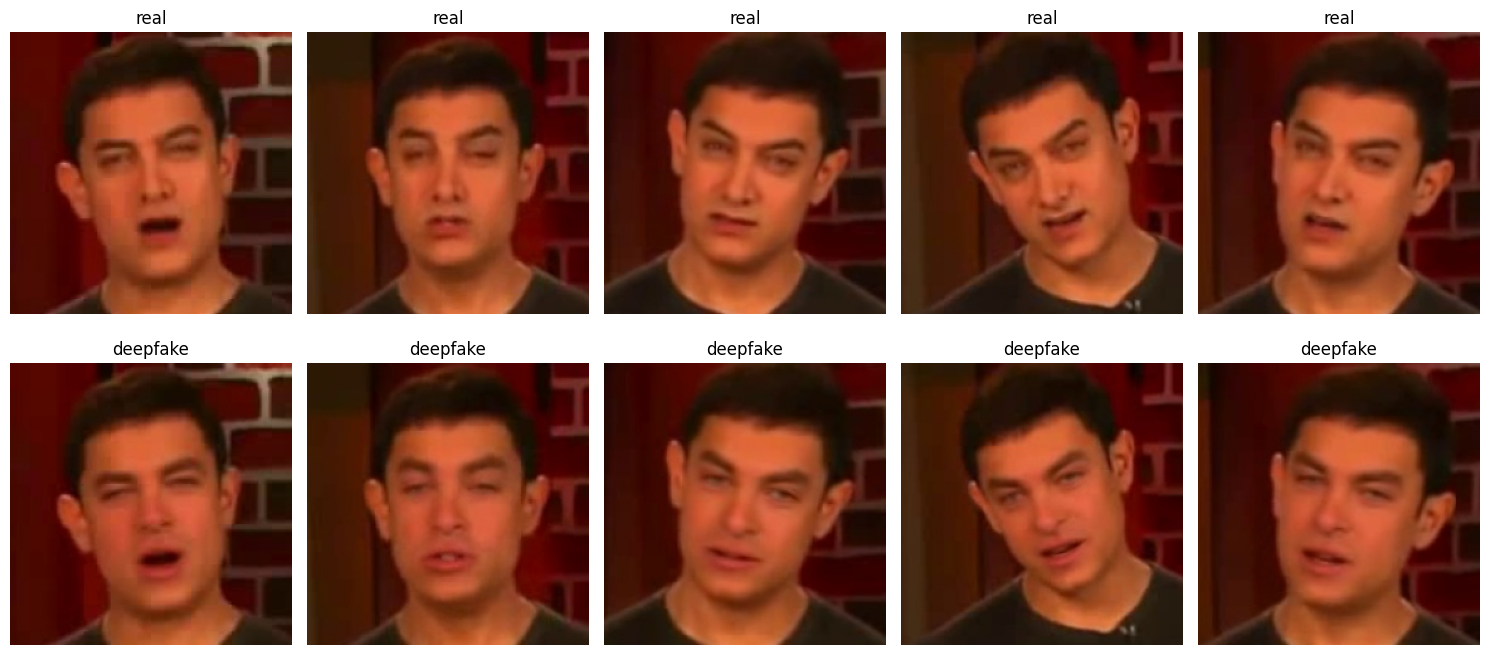

In [28]:

# ============================================================
# DAY 9: DISPLAY SAMPLE FACE CROPS
# ============================================================

import matplotlib.pyplot as plt
import cv2

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for row_idx, class_name in enumerate(["real", "deepfake"]):

    samples = face_metadata_v2[
        face_metadata_v2["class_name"] == class_name
    ].head(5)

    for col_idx, (_, record) in enumerate(samples.iterrows()):

        image_path = PROJECT_ROOT / record["face_path"]
        image = cv2.imread(str(image_path))

        if image is not None:
            image = cv2.cvtColor(
                image, cv2.COLOR_BGR2RGB
            )

            axes[row_idx, col_idx].imshow(image)
            axes[row_idx, col_idx].set_title(class_name)

        axes[row_idx, col_idx].axis("off")

plt.tight_layout()
plt.show()


In [29]:

print("=" * 50)
print("DAY 9 FINAL SUMMARY")
print("=" * 50)

print("Input videos:", len(cleaned_metadata_df))
print("Extracted face crops:", len(face_metadata_v2))

print("\nReal crops:",
      (face_metadata_v2["label"] == 0).sum())

print("Deepfake crops:",
      (face_metadata_v2["label"] == 1).sum())

print("\nAll image files exist:",
      face_metadata_v2["file_exists"].all())

print("\nMetadata file exists:",
      (RESULTS_DIR / "face_metadata_v2.csv").exists())


DAY 9 FINAL SUMMARY
Input videos: 6529
Extracted face crops: 64944

Real crops: 8798
Deepfake crops: 56146

All image files exist: True

Metadata file exists: True


In [31]:
# face dataset quality checking
# DAY 10: FACE DATASET QUALITY CHECKING

face_metadata_df = face_metadata_v2.copy()

face_metadata_df["file_exists"] = face_metadata_df["face_path"].apply(
    lambda x: (PROJECT_ROOT / x).exists()
)

print("Total face records:", len(face_metadata_df))
print("\nFile existence:")
print(face_metadata_df["file_exists"].value_counts())

print("\nClass distribution:")
print(face_metadata_df["class_name"].value_counts())

Total face records: 64944

File existence:
file_exists
True    64944
Name: count, dtype: int64

Class distribution:
class_name
deepfake    56146
real         8798
Name: count, dtype: int64


In [32]:
# check image dimension
def get_image_size(relative_path):

    path = PROJECT_ROOT / relative_path

    image = cv2.imread(str(path))

    if image is None:
        return None

    return image.shape[:2] 



face_metadata_df["image_size"] = face_metadata_df["face_path"].apply(
    get_image_size
)

print(face_metadata_df["image_size"].value_counts().head())

image_size
(224, 224)    64944
Name: count, dtype: int64


# day 11

In [33]:
#video level split
#data leakage avoid karenge
#Unique videos

video_df = face_metadata_df[
    ["video_path", "video_id", "label", "class_name"]
].drop_duplicates()

video_df = video_df.reset_index(drop=True)

print("Unique videos:", len(video_df))
display(video_df.head())


Unique videos: 6528


,video_path,video_id,label,class_name
0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,Celeb-real__id0_0000,0,real
1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,Celeb-real__id0_0001,0,real
2,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,Celeb-real__id0_0002,0,real
3,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,Celeb-real__id0_0003,0,real
4,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,Celeb-real__id0_0004,0,real


In [34]:
# train/test split
from sklearn.model_selection import train_test_split
train_videos, test_videos = train_test_split(
    video_df,
    test_size=0.20,
    random_state=42,
    stratify=video_df["label"]
)

train_videos, val_videos = train_test_split(
    train_videos,
    test_size=0.20,
    random_state=42,
    stratify=train_videos["label"]
)

print("Train videos:", len(train_videos))
print("Validation videos:", len(val_videos))
print("Test videos:", len(test_videos))

Train videos: 4177
Validation videos: 1045
Test videos: 1306


In [35]:
# Create split mapping
train_videos = train_videos.copy()
val_videos = val_videos.copy()
test_videos = test_videos.copy()

train_videos["split"] = "train"
val_videos["split"] = "val"
test_videos["split"] = "test"

video_split_df = pd.concat(
    [train_videos, val_videos, test_videos],
    ignore_index=True
)

display(video_split_df.head())

,video_path,video_id,label,class_name,split
0,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,Celeb-real__id26_0006,0,real,train
1,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,Celeb-synthesis__id54_id55_0005,1,deepfake,train
2,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,Celeb-synthesis__id29_id30_0002,1,deepfake,train
3,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,Celeb-synthesis__id8_id3_0002,1,deepfake,train
4,c:\Users\HIMANSHU\Desktop\minor project 1\Mino...,Celeb-synthesis__id43_id42_0002,1,deepfake,train


In [36]:
# add split to face metedata
face_metadata_df = face_metadata_df.drop(
    columns=["split"],
    errors="ignore"
)

face_metadata_df = face_metadata_df.merge(
    video_split_df[
        ["video_id", "split"]
    ],
    on="video_id",
    how="left"
)

print(face_metadata_df["split"].value_counts())


split
train    41554
test     12996
val      10394
Name: count, dtype: int64


# DAY 12

In [37]:
#Leakage verification
split_check = (
    face_metadata_df
    .groupby("video_id")["split"]
    .nunique()
)

print(
    "Videos appearing in multiple splits:",
    (split_check > 1).sum()
)

Videos appearing in multiple splits: 0


class_name,deepfake,real
split,,
test,11232,1764
train,35920,5634
val,8994,1400


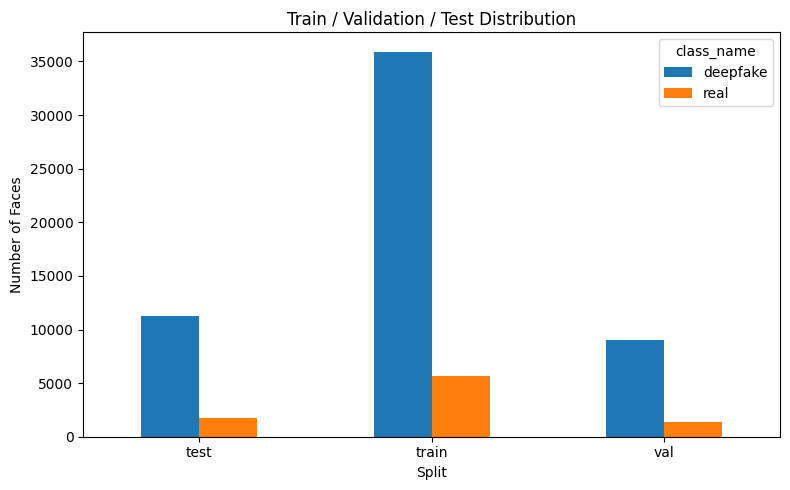

In [38]:
#class distribution
split_distribution = pd.crosstab(
    face_metadata_df["split"],
    face_metadata_df["class_name"]
)

display(split_distribution)

split_distribution.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Train / Validation / Test Distribution")
plt.xlabel("Split")
plt.ylabel("Number of Faces")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# DAY 13

In [39]:
# save final metadata

final_metadata_path = RESULTS_DIR / "final_face_metadata.csv"

face_metadata_df.to_csv(
    final_metadata_path,
    index=False
)

video_split_path = RESULTS_DIR / "video_split_metadata.csv"

video_split_df.to_csv(
    video_split_path,
    index=False
)

print("Saved:")
print(final_metadata_path)
print(video_split_path)

Saved:
c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\final_face_metadata.csv
c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\video_split_metadata.csv


# DAY 14

In [40]:
#pytorch dataset preparation
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

In [41]:
# transform
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [42]:
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [43]:
# dataset class
class DeepfakeDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image_path = PROJECT_ROOT / row["face_path"]

        image = Image.open(image_path).convert("RGB")

        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [44]:
# create datasets
train_df = face_metadata_df[
    face_metadata_df["split"] == "train"
].copy()

val_df = face_metadata_df[
    face_metadata_df["split"] == "val"
].copy()

test_df = face_metadata_df[
    face_metadata_df["split"] == "test"
].copy()

print("Train faces:", len(train_df))
print("Validation faces:", len(val_df))
print("Test faces:", len(test_df))

Train faces: 41554
Validation faces: 10394
Test faces: 12996


In [45]:
#pytorch dataset
train_dataset = DeepfakeDataset(
    train_df,
    transform=train_transform
)

val_dataset = DeepfakeDataset(
    val_df,
    transform = val_test_transform
)

test_dataset = DeepfakeDataset(
    test_df,
    transform=val_test_transform
)

print("Datasets created successfully.")

Datasets created successfully.


In [46]:
#dataLoader
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


In [ ]:
# final test
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10])

c:\Users\HIMANSHU\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
